In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
file_path = "temp/finalcoincs.bin"
column_names = ["id1", "id2", "x", "y", "z", "dx1", "dy1", "dz1", "dx2", "dy2", "dz2"]
column_types = [np.int16, np.int16, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32]
num_cols = len(column_types)
dtype = np.dtype({'names': column_names, 'formats': column_types})
data = np.fromfile(file_path, dtype=dtype)
print(len(data))
print(data[0:10])

4152752
[(4252, 3432,  107.17   ,  -55.5747,  -3.87605, -0.966453,  0.25565  ,  0.0247183 ,  0.966453, -0.25565  , -0.0247183 )
 (3686,   10, -100.896  ,   63.8477, -34.3884 , -0.939189, -0.340233 ,  0.0465312 ,  0.939189,  0.340233 , -0.0465312 )
 (5933, 1868,   24.7728 , -117.71  ,  15.3709 ,  0.975141, -0.221372 ,  0.00966986, -0.975141,  0.221372 , -0.00966986)
 ( 156, 2813,   53.3954 ,  107.291 , -10.9082 ,  0.899306,  0.437221 , -0.00927777, -0.899306, -0.437221 ,  0.00927777)
 (2362, 5733,  105.56   ,   56.3662,  -1.71409,  0.925067, -0.346352 ,  0.155855  , -0.925067,  0.346352 , -0.155855  )
 ( 215, 5052,   -2.13641, -120.562 ,  17.202  ,  0.974679,  0.151896 ,  0.164099  , -0.974679, -0.151896 , -0.164099  )
 ( 781, 5596,  -23.1024 ,  118.098 ,  31.0059 ,  0.996085,  0.0218522, -0.0856582 , -0.996085, -0.0218522,  0.0856582 )
 (5406,  710,   33.0884 , -115.494 ,  11.6842 , -0.993352, -0.0626855, -0.0965571 ,  0.993352,  0.0626855,  0.0965571 )
 (2621,  603,  118.713  ,  -16.8

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

-121.0 120.997
-120.999 120.998
-54.9999 54.9999


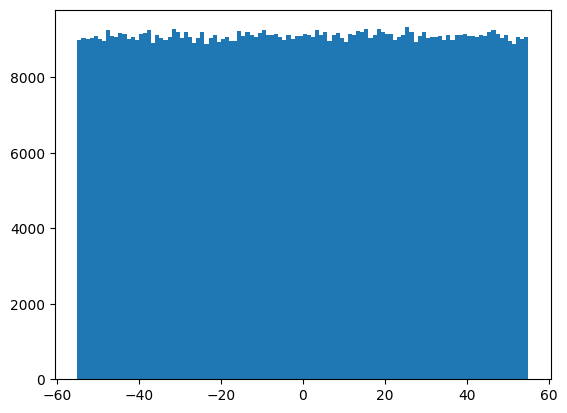

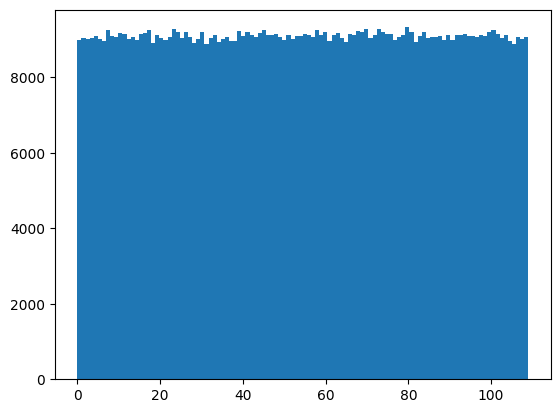

1000000


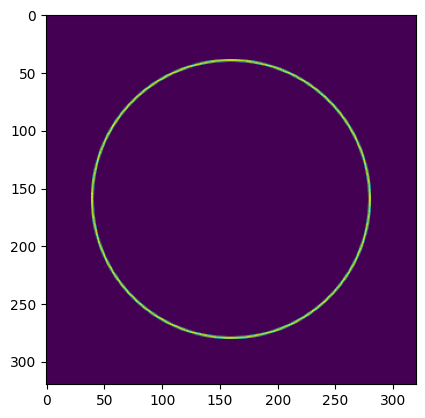

In [ ]:
file_path = 'temp/positions.txt'
positions = pd.read_csv(file_path, sep=' ', header=None, usecols=[1,2,3,4,5,6,7,8,9])
print(np.min(positions.iloc[:, 0]), np.max(positions.iloc[:, 0]))
print(np.min(positions.iloc[:, 1]), np.max(positions.iloc[:, 1]))
print(np.min(positions.iloc[:, 2]), np.max(positions.iloc[:, 2]))
genimg = np.zeros((320, 320, 110), dtype=np.int32)  # int32 to avoid overflow in bincount

# Get coordinates and move to appropriate bins
inds = positions.iloc[:, [0, 1, 2]].to_numpy()
plt.hist(inds[:,2], bins = 110)
plt.show()
inds = inds + np.array([160, 160, 55])
inds = np.floor(inds).astype(int)
plt.hist(inds[:,2], bins = 110)
plt.show()
# Mask invalid indices
valid_mask = (
    (inds[:, 0] >= 0) & (inds[:, 0] < 320) &
    (inds[:, 1] >= 0) & (inds[:, 1] < 320) &
    (inds[:, 2] >= 0) & (inds[:, 2] < 110)
)
inds_valid = inds[valid_mask]

# Convert 3D indices to flat indices
flat_inds = np.ravel_multi_index(
    (inds_valid[:, 0], inds_valid[:, 1], inds_valid[:, 2]),
    dims=genimg.shape
)

# Use bincount for fast accumulation
counts = np.bincount(flat_inds, minlength=genimg.size)
genimg = counts.reshape(genimg.shape).astype(np.int16)  # back to original dtype

print(np.sum(genimg))
plt.imshow(np.sum(genimg, axis = 2))

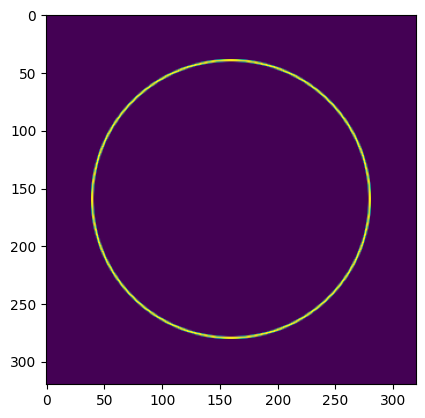

999999602


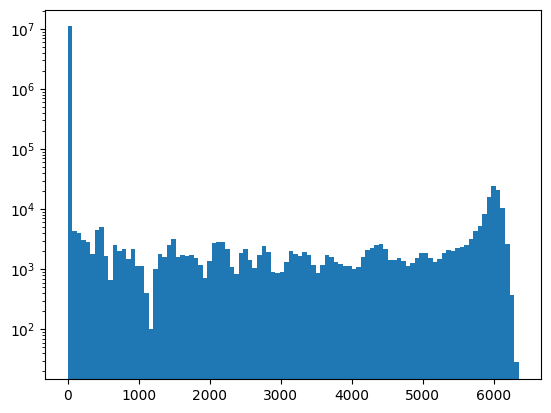

In [3]:
file_path = 'temp/genhist.bin'
genimg = np.fromfile(file_path, dtype = np.int16).reshape((320, 320, 110))
plt.imshow(np.sum(genimg, axis = 2))
plt.show()
plt.hist(genimg.flatten(), bins = 100)
print(np.sum(genimg))
plt.yscale('log')
plt.show()